 Name Taherunnesa Rahi

Labpartner(s) Muhtasim Haque nahian

In [ ]:
#import statements go here


# Class 12.2

# Warmup 12.2

Follow up with working on logging into the LSU HPC and finishing the warmup from last time. You may need to run a vpn. Let's get everyone spun up on this. If you're already there, help your fellow students and go dig into the documentation more. We'll do some more on this next week. Report here 1) have you been able to ssh in? 2) have you been able to access the ondemand site and open a jupyter notebook?

# Lecture 12.2

### Announcements
  
We are going to do an advanced lab today!


### Agenda
- Predator prey modeling. We are going to actually do some scientific modelng today!

## Predator Prey Modeling

See what this lab was based on here: 

https://github.com/numerical-mooc/assignment-bank/blob/master/Lessons.and.Assignments/Predator.Prey.Model/Predator.Prey.Model.ipynb

For a more advanced example in predator prey modeling:

https://waterprogramming.wordpress.com/tag/predator-prey/

Modeling the zombie aplocalypse:

https://scipy-cookbook.readthedocs.io/items/Zombie_Apocalypse_ODEINT.html



###  12.2.1 Lotka-Volterra Equations

The Lotka–Volterra equations, also known as the predator–prey equations, are a pair of first-order, non-linear, differential
equations. They are frequently used to describe the dynamics of biological systems in which two species interact, one as a predator and
the other as prey. You can read more about this from Wikipedia <http://en.wikipedia.org/wiki/Lotka-Volterra_equation>.

#### Equations describing the system

 Their populations change with time according to the following pair of equations:

$ dx/dt = x ( \alpha - \beta y  ) $

$ dy/dt = -y( \gamma - \delta x ) $

Where, $x$ is the number of prey (e.g., phytoplankton), $y$ is the number of predators (e.g., zooplankton). $dx/dt, dy/dt$ gives the rate of change of their respective populations over 
time $t$. $\alpha, \beta, \gamma, \delta $ are the parameters describing the interaction between the two species. This models makes some assumptions about 
the predator and prey. You can read about them from the Wikipedia page mentioned above.

The above equations can be written in a slightly different form to interpret the physical meaning of the four parameters used.

1.Rate equation for prey

$dx/dt = \alpha x - \beta x y $

The prey population (x) is presumed to have unlimited supply of food, $\alpha x$ represents the rate of population growth of prey. Rate of decrease of population of prey is assumed to be proportional to the rate at which predator and prey encounter each other, given by $ \beta y x$

2.Rate equation for predator

$ dy/dt = \delta x y -\gamma y $

For the predator population (y), $\delta x y $ gives the rate of growth of predator population. Note that this is similar to the rate of decrease of population of prey. The second term $\gamma y $ gives the rate of population decrease for predators due to natural death or emigration.

### 12.2.2 Numerical solution using Python

A simple python code for solving these equations is shown below.

In [43]:
# import required libraries
import numpy as np
import matplotlib.pyplot as plt

In [6]:
# set the parameters. I just took these from one of the samples, we will play around with them later
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

In [20]:
#define the time stepping scheme - Euler forward or "shooting" method

def euler_step(u, f, dt):
    """Returns the solution at the next time-step using Euler's method.
    
    Parameters
    ----------
    u : array of float
        solution at the previous time-step.
    f : function
        function to compute the right hand-side of the system of equation.
    dt : float
        time-increment.
    
    Returns
    -------
    u_n_plus_1 : array of float
        approximate solution at the next time step.
    """
    
    return u + dt * f(u)

In [21]:
# define the function that represents the Lotka-Volterra equations
# u is the x,y state of the system, what the population is at a given time.
# u = [x,y] on array with both the predetor and prey variables

def f(u):
    """Returns the rate of change of species
    
    Parameters
    ----------
    u : array of float
        array containing the solution at time n.
        
    Returns
    -------
    dudt : array of float
        array containing the RHS given u.
    """
    x = u[0]
    y = u[1]
    return np.array([x*(alpha - beta*y), -y*(gamma - delta*x)]) #these will give the rates of change,not populations


In [22]:
# Now solve the system


# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.01                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])


In [23]:
u_euler

array([[10.,  2.],
       [ 0.,  0.],
       [ 0.,  0.],
       ...,
       [ 0.,  0.],
       [ 0.,  0.],
       [ 0.,  0.]], shape=(1501, 2))

In [24]:
n = 0
u_euler[n+1] = euler_step(u_euler[n], f, dt)

In [25]:
u_euler

array([[10.  ,  2.  ],
       [ 9.86,  2.12],
       [ 0.  ,  0.  ],
       ...,
       [ 0.  ,  0.  ],
       [ 0.  ,  0.  ],
       [ 0.  ,  0.  ]], shape=(1501, 2))

In [26]:
n = 1
u_euler[n+1] = euler_step(u_euler[n], f, dt)

In [27]:
u_euler

array([[10.       ,  2.       ],
       [ 9.86     ,  2.12     ],
       [ 9.7077616,  2.244232 ],
       ...,
       [ 0.       ,  0.       ],
       [ 0.       ,  0.       ],
       [ 0.       ,  0.       ]], shape=(1501, 2))

In [28]:
# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

In [29]:
u_euler

array([[10.        ,  2.        ],
       [ 9.86      ,  2.12      ],
       [ 9.7077616 ,  2.244232  ],
       ...,
       [ 0.87954346,  0.04493602],
       [ 0.88786462,  0.04353381],
       [ 0.89627944,  0.04217898]], shape=(1501, 2))

We will now plot the variation of population for each species with time.

In [30]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

Text(0.5, 1.0, 'predator prey model')

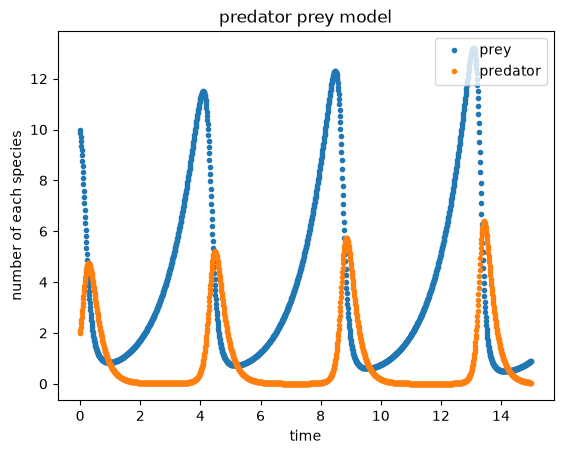

In [31]:
plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Let's think a bit about what this solution means, what is going on here?

What happens if we start with different initial conditions? Like more prey and less predators.

In [32]:
# initial conditions (initial populations):
x0 = 15. # initial prey amount
y0 = 0.001 # initial predator amount
t0 = 0.

In [33]:
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

In [34]:
# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

What happened?

Text(0.5, 1.0, 'predator prey model')

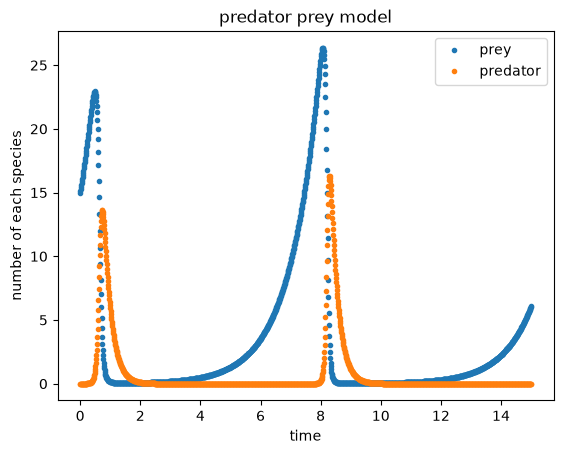

In [35]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

What if we start with the same amount of prey and predators?

In [36]:
# set the parameters
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

In [37]:
# initial conditions (initial populations):
x0 = 5. # initial prey amount
y0 = 5 # initial predator amount
t0 = 0.

In [38]:
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

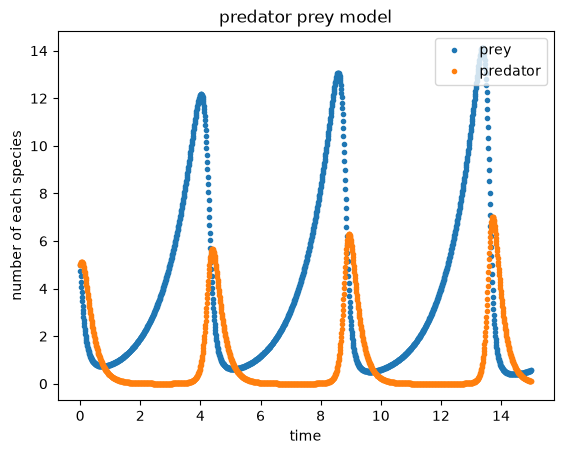

In [39]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

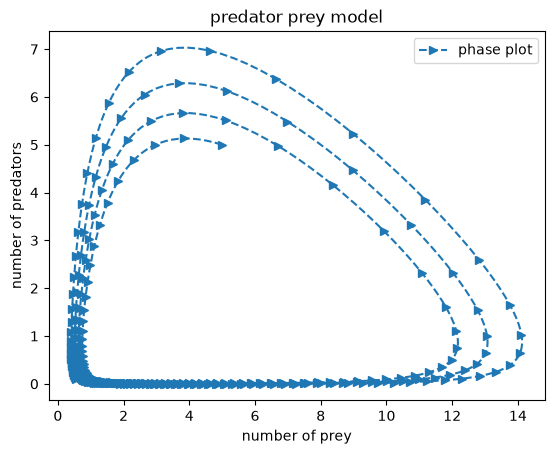

In [40]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

What happened?

Let's mess around with the model parameters. What if the prey grow faster?

In [41]:
# set the parameters
alpha = 10.
beta = 1.2
gamma = 4.
delta = 1.

In [42]:
# initial conditions (initial populations):
x0 = 5. # initial prey amount
y0 = 5 # initial predator amount
t0 = 0.

In [43]:
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

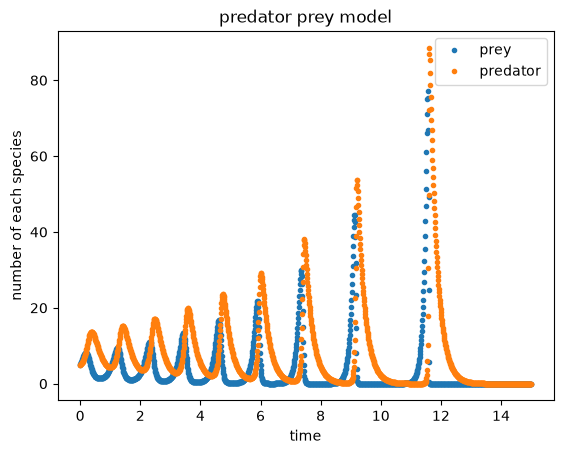

In [44]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

What happened?

### 12.2.3 System behavior

A better understanding of the system behavior can be obtained by a phase plot of the population of predators vs. the population of prey. It will tell us if the system sustains or collapses over time. For the choice of parameters $ \alpha, \beta, \gamma $ and $ \delta $ made above, we see that the maximum population of each species keeps increasing each cycle. You can read more about that in the Wikipedia link mentioned above.

Text(0.5, 1.0, 'predator prey model')

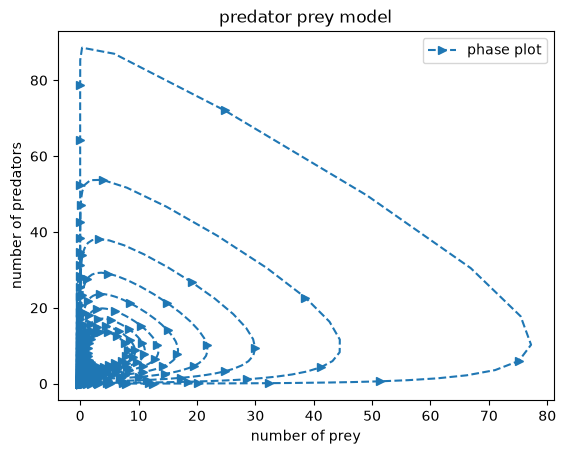

In [45]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

# Lab 12.2

#### E.1 How does timestep affect the solution?
Modify the timestep (or time increment) dt. How does this affect your solutions? Plot both the timeseries and the phase plots. Try making dt 10 times bigger (dt = 0.1) and 10 times smaller. Describe what happens to your results. What happens if you make dt 100 times smaller?

#### A)Test to change DT to 10 times bigger

In [54]:
# set the parameters. I just took these from one of the samples, we will play around with them later
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

In [55]:
# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.1                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

In [56]:
N

151

In [57]:
# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

In [58]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)  #for 15 years a time array for plotting
x_euler = u_euler[:,0]    #prey
y_euler = u_euler[:,1]    #predator

Text(0.5, 1.0, 'predator prey model')

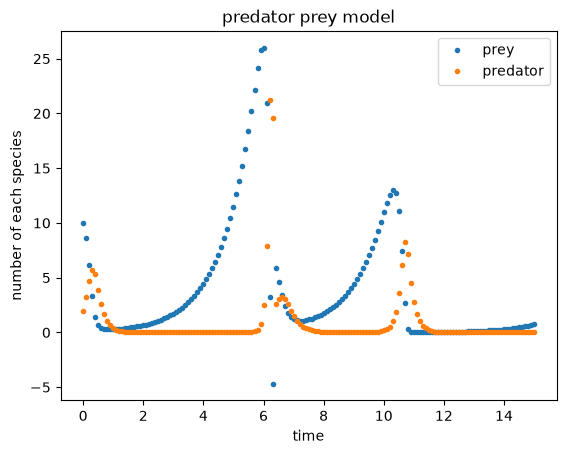

In [59]:
plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

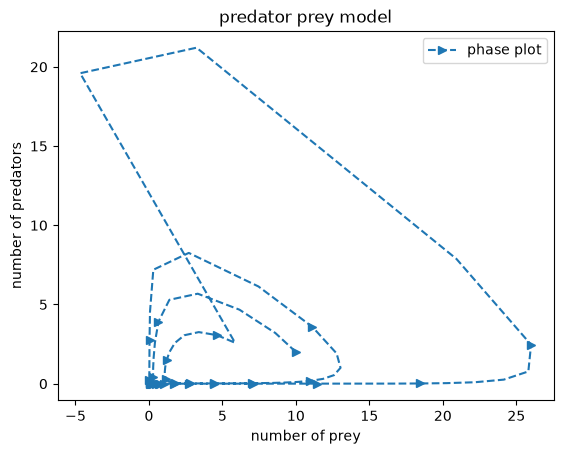

In [60]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

#### B) Test to change DT to 10 times smaller

In [61]:
#define conditions
# set time-increment and discretize the time
T  = 15.0                           # final time eg 15 years
dt = 0.001                          # set time-increment rate or steps (time increment)
N  = int(T/dt) + 1                  # number of time-steps 

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

#create the array where the solutions of populations predicted for the prey predator will be saved
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

In [62]:
N

15001

In [63]:
# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

In [64]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)  #for 15 years a time array for plotting
x_euler = u_euler[:,0]    #prey
y_euler = u_euler[:,1]    #predator

Text(0.5, 1.0, 'predator prey model')

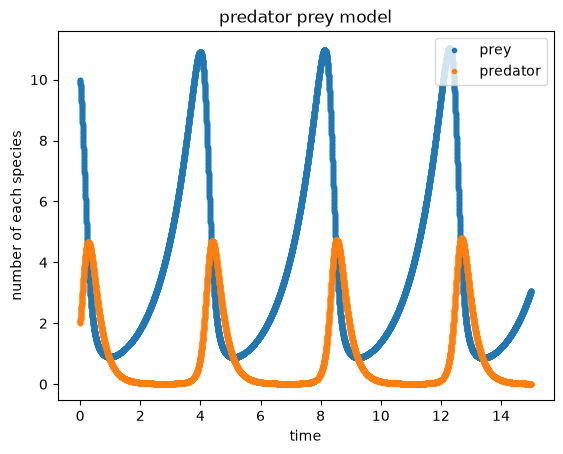

In [65]:
plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

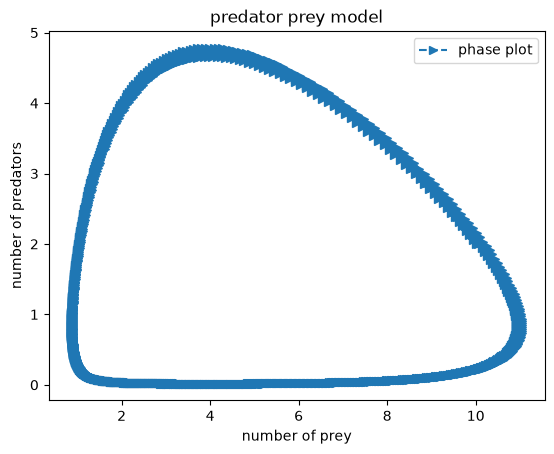

In [66]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

#### C) 100 times smaller

In [67]:
#define conditions
# set time-increment and discretize the time
T  = 15.0                           # final time eg 15 years
dt = 0.0001                          # set time-increment rate or steps (time increment)
N  = int(T/dt) + 1                  # number of time-steps 

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

#create the array where the solutions of populations predicted for the prey predator will be saved
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

In [68]:
N

150001

In [69]:
# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

In [70]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)  #for 15 years a time array for plotting
x_euler = u_euler[:,0]    #prey
y_euler = u_euler[:,1]    #predator

Text(0.5, 1.0, 'predator prey model')

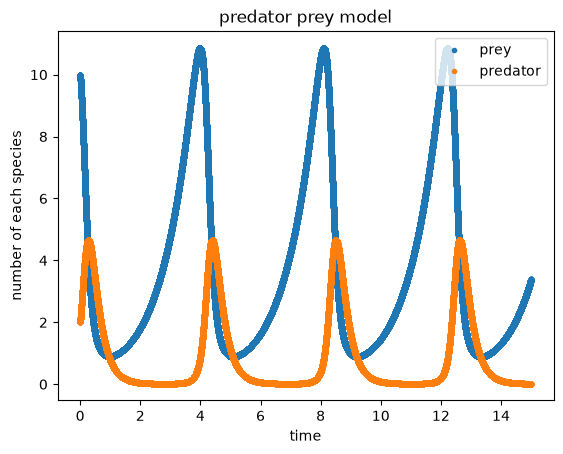

In [71]:
plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

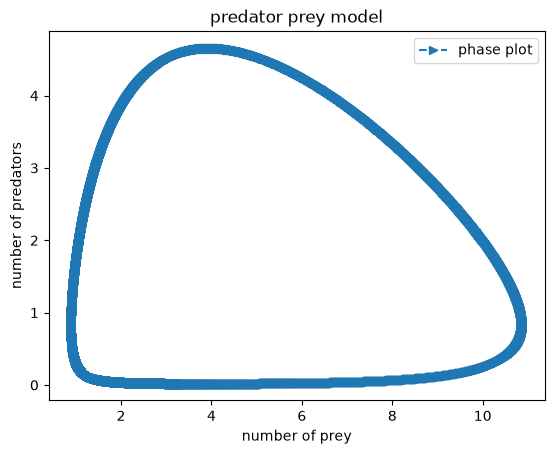

In [72]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

When the time step increased to 0.1, the population cycles became irregular, and the prey population dropped below zero, which is not possible. It shows a numerical error. When the time step decreased to 0.001 and 0.0001, the cycles became more consistent. Smaller time steps represent the recovery cycle more accurately.

#### E.2 Adding the steady state

The steady state(s) of the system are found by setting the population equations to zero, that is the solution to when the population is not changing. This is also called a "fixed point" of the equations, since if the populations start there they stay there, i.e. are fixed.

Find the steady states of the system using algebra. Plot the fixed point (steady state population) of the system on both the timeseries and phase space plots. Describe where the fixed point is in the phase space plot and plot it. What happens if you start at the steady state? What happens if you start near the steady state?

$\alpha x - \beta x y  = 0$

$\delta x y -\gamma y  = 0$



One solution is x=0, y=0
Another is y=alpha/beta, x=gama/delta

In [44]:
alpha = 1.
beta = 1.2
gamma = 4
delta = 1

def euler_step(u, f, dt):
    return u + dt * f(u)

def f(u):
    x = u[0]
    y = u[1]
    return np.array([x * (alpha - beta * y), -y * (gamma - delta * x)])

T = 15.0
dt = 0.01
N = int(T / dt) + 1

#Same number of prey and predator from past example
x0 = 10.
y0 = 2.
t0 = 0

#applying the function
u_euler = np.zeros((N, 2))
u_euler[0] = np.array([x0, y0])

for n in range(N - 1):
    u_euler[n + 1] = euler_step(u_euler[n], f, dt)

time = np.linspace(0.0, T, N)
x_euler = u_euler[:, 0]
y_euler = u_euler[:, 1]

#Steady state
x_st = gamma / delta
y_st = alpha / beta

In [90]:
print(x_st)
print(y_st)

4.0
0.8333333333333334


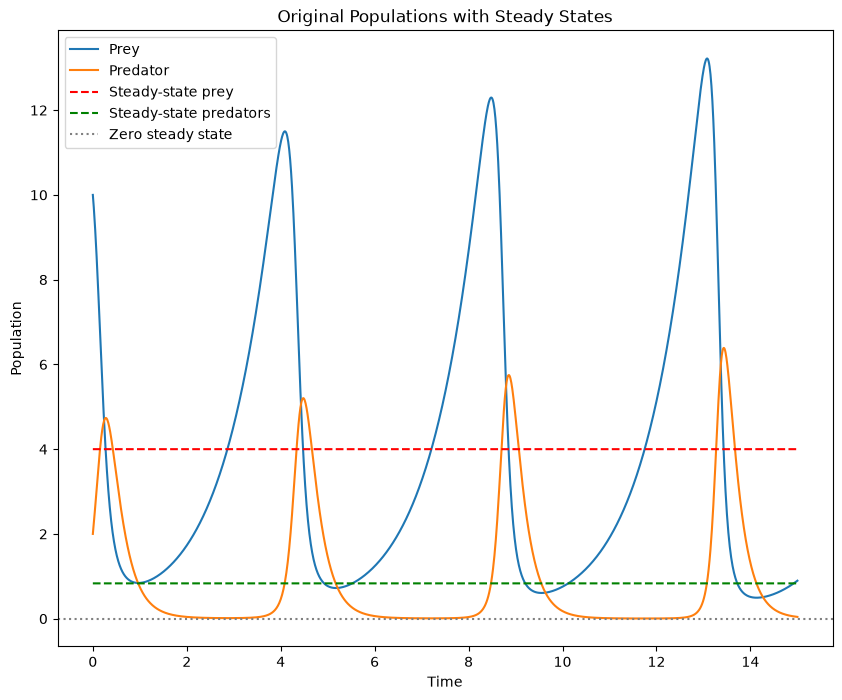

In [45]:


# Time-series plot

plt.plot(time, x_euler, label='Prey')
plt.plot(time, y_euler, label='Predator')

plt.plot(time, x_st * np.ones(N), '--',
         color='red', label='Steady-state prey')
plt.plot(time, y_st * np.ones(N), '--',
         color='green', label='Steady-state predators')
plt.axhline(0, color='gray', linestyle=':',
            label='Zero steady state')

plt.xlabel('Time')
plt.ylabel('Population')
plt.title('Original Populations with Steady States')
plt.legend()
plt.show()



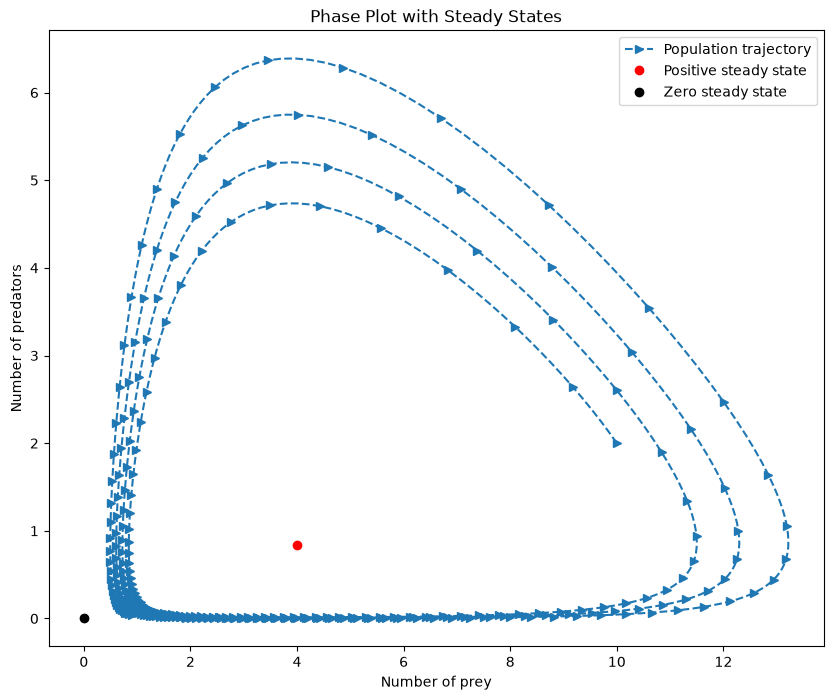

In [46]:
plt.plot(x_euler, y_euler,'-->',markevery=5, label='Population trajectory')
plt.plot(x_st, y_st, 'ro', label='Positive steady state')
plt.plot(0, 0, 'ko', label='Zero steady state')

plt.xlabel('Number of prey')
plt.ylabel('Number of predators')
plt.title('Phase Plot with Steady States')
plt.legend()
plt.show()

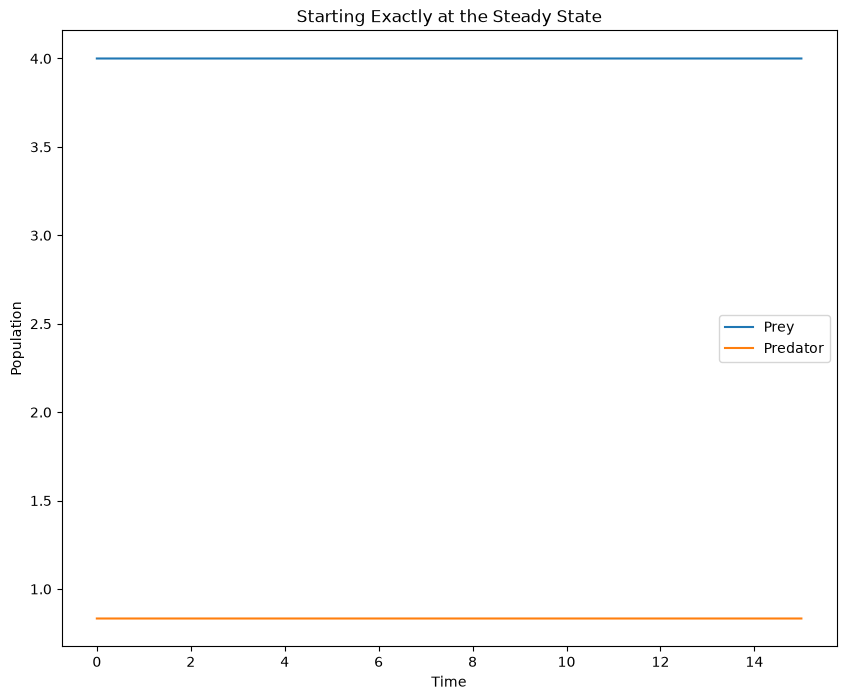

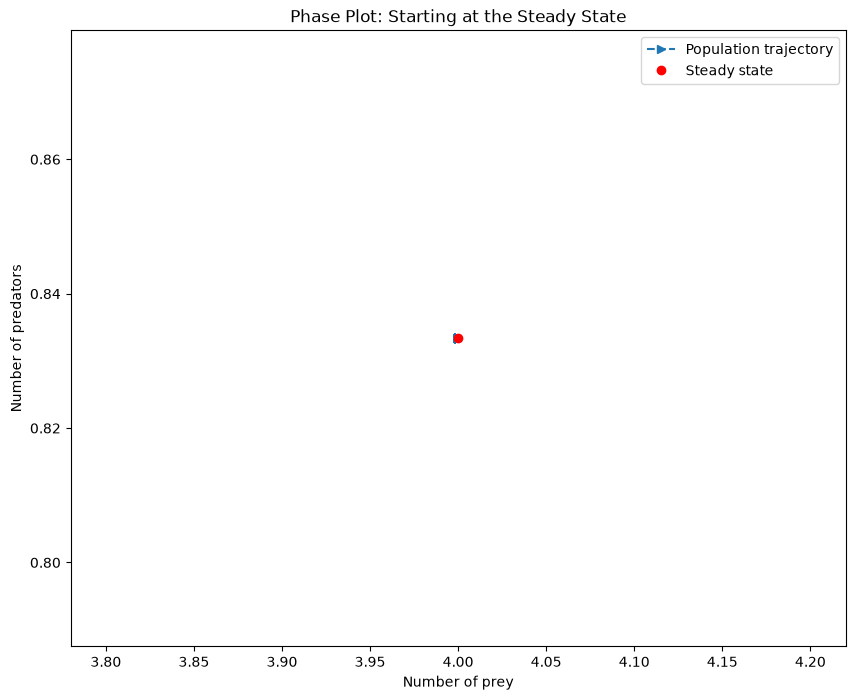

In [48]:
# Start exactly at the positive steady state
x0 = x_st
y0 = y_st

u_euler = np.zeros((N, 2))
u_euler[0] = np.array([x0, y0])

for n in range(N - 1):
    u_euler[n + 1] = euler_step(u_euler[n], f, dt)

x_euler = u_euler[:, 0]
y_euler = u_euler[:, 1]

# Time-series plot
plt.figure()

plt.plot(time, x_euler, label='Prey')
plt.plot(time, y_euler, label='Predator')

plt.xlabel('Time')
plt.ylabel('Population')
plt.title('Starting Exactly at the Steady State')
plt.legend()
plt.show()

# Phase plot: use dots to show the stationary populations
plt.figure()

plt.plot(x_euler, y_euler, '-->', markevery=5, label='Population trajectory')
plt.plot(x_st, y_st, 'ro', label='Steady state')

plt.xlabel('Number of prey')
plt.ylabel('Number of predators')
plt.title('Phase Plot: Starting at the Steady State')
plt.legend()
plt.show()

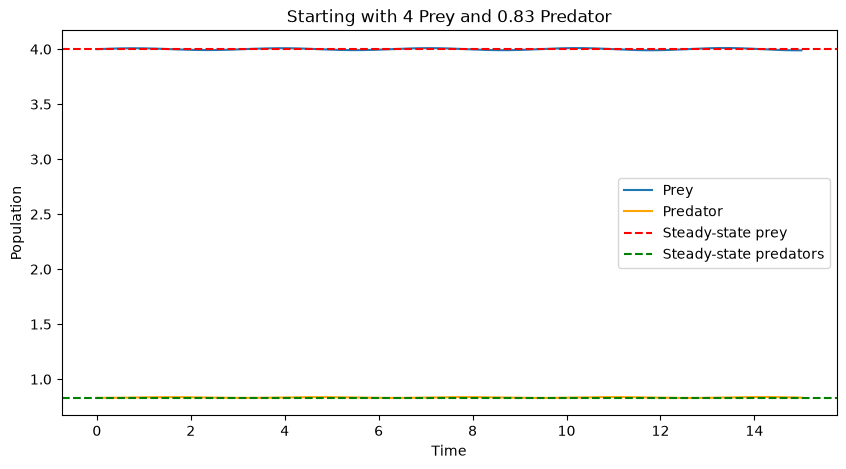

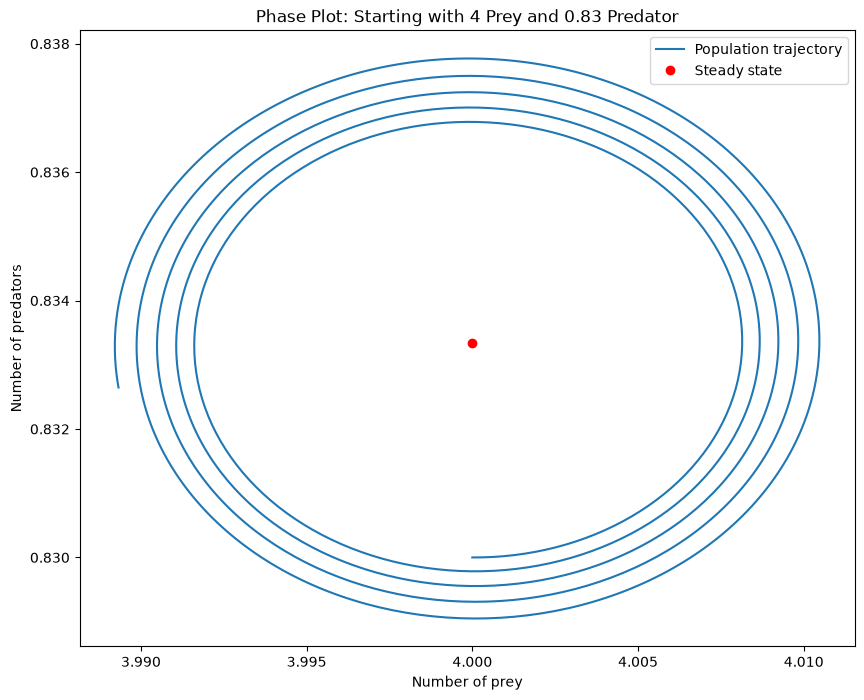

In [50]:
# Start near the positive steady state
x0 = 4.
y0 = 0.83

u_euler = np.zeros((N, 2))
u_euler[0] = np.array([x0, y0])

for n in range(N - 1):
    u_euler[n + 1] = euler_step(u_euler[n], f, dt)

time = np.linspace(0.0, T, N)
x_euler = u_euler[:, 0]
y_euler = u_euler[:, 1]

# Time-series plot: both populations on one plot
plt.figure(figsize=(10, 5))

plt.plot(time, x_euler, label='Prey')
plt.plot(time, y_euler, color='orange', label='Predator')

plt.axhline(x_st, color='red', linestyle='--',
            label='Steady-state prey')
plt.axhline(y_st, color='green', linestyle='--',
            label='Steady-state predators')

plt.xlabel('Time')
plt.ylabel('Population')
plt.title('Starting with 4 Prey and 0.83 Predator')
plt.legend()
plt.show()

# Phase plot
plt.figure()

plt.plot(x_euler, y_euler, label='Population trajectory')
plt.plot(x_st, y_st, 'ro', label='Steady state')

plt.xlabel('Number of prey')
plt.ylabel('Number of predators')
plt.title('Phase Plot: Starting with 4 Prey and 0.83 Predator')
plt.legend()
plt.show()

The steady-state population levels for prey and predator are 4 and 0.83 respectively. If the predator and prey populations begin at these values, the system remains static and unchanged. When the initial values are close to the steady-state numbers, the system remains nearly stable

#### E.3 A better algorithm
Do Exercise 1 again with a fourth order time stepping method called "Runge-Kutta 4" whose algorithm is given below. How do your answers differ? How does the dt, the timestep, affect your answer using this "higher order" algorithm?

In [1]:
def RK4(u,f,dt):
    # Runge Kutta 4th order method
    """Returns the solution at the next time-step using Runge Kutta fourth order (RK4) method.
    
    Parameters
    ----------
    u : array of float
        solution at the previous time-step.
    f : function
        function to compute the right hand-side of the system of equation.
    dt : float
        time-increment.
    
    Returns
    -------
    u_n_plus_1 : array of float
        approximate solution at the next time step.
    """
    #calculate slopes
    k1 = f(u)
    u1 = u + (dt/2.)*k1
    k2 = f(u1)
    u2 = u + (dt/2.)*k2
    k3 = f(u2)
    u3 = u + dt*k3
    k4 = f(u3)
    return u + (dt/6.)*(k1 + 2.*k2 + 2.*k3 + k4)

In [2]:
def f(u):
    x = u[0]
    y = u[1]
    return np.array([x * (alpha - beta * y), -y * (gamma - delta * x)])

In [7]:
T  = 15.0                           
dt = 0.01                           
N  = int(T/dt) + 1                   

# initial conditions
x0 = 10.
y0 = 2. 
t0 = 0.

# initialize the array containing the solution for each time-step
u_rk4 = np.zeros((N, 2))

# input initial conditions
u_rk4[0] = np.array([x0, y0])

for n in range(N - 1):
    u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

time = np.linspace(0.0, T, N)
x_rk4 = u_rk4[:, 0]
y_rk4 = u_rk4[:, 1]

Text(0.5, 1.0, 'Predator Prey model')

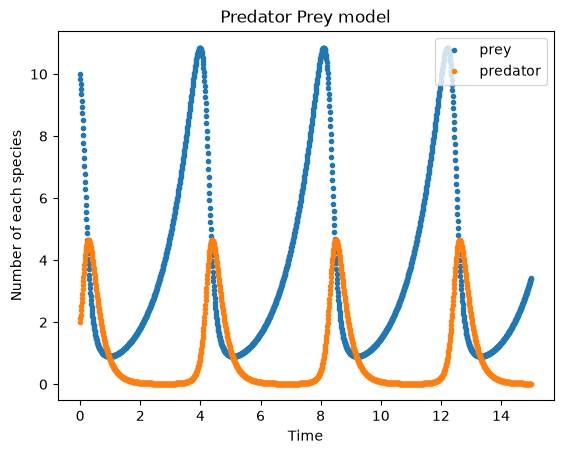

In [9]:
plt.plot(time, x_rk4, '.', label = 'prey ')
plt.plot(time, y_rk4, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("Time")
plt.ylabel("Number of each species")
#title
plt.title("Predator Prey model")

Text(0.5, 1.0, 'Predator Prey model')

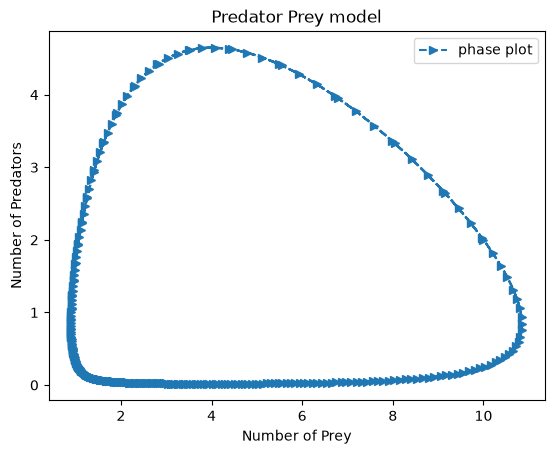

In [10]:
plt.plot(x_rk4, y_rk4, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("Number of Prey")
plt.ylabel("Number of Predators")
#title
plt.title("Predator Prey model")

In [11]:
T  = 15.0                           
dt = 0.1            #10 times bigger                  
N  = int(T/dt) + 1                   

# initial conditions
x0 = 10.
y0 = 2. 
t0 = 0.

# initialize the array containing the solution for each time-step
u_rk4 = np.zeros((N, 2))

# input initial conditions
u_rk4[0] = np.array([x0, y0])

for n in range(N - 1):
    u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

time = np.linspace(0.0, T, N)
x_rk4 = u_rk4[:, 0]
y_rk4 = u_rk4[:, 1]

Text(0.5, 1.0, 'Predator Prey model')

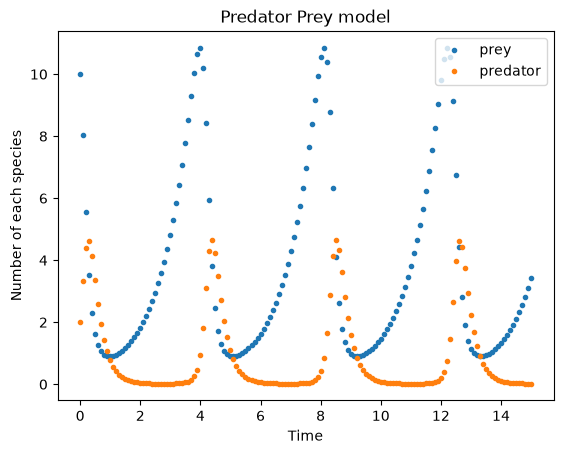

In [12]:
plt.plot(time, x_rk4, '.', label = 'prey ')
plt.plot(time, y_rk4, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("Time")
plt.ylabel("Number of each species")
#title
plt.title("Predator Prey model")

Text(0.5, 1.0, 'Predator Prey model')

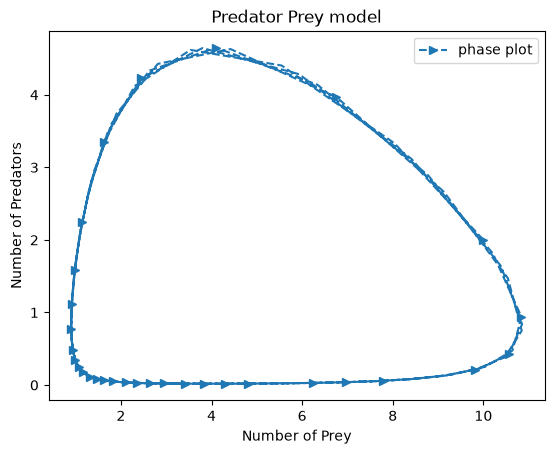

In [14]:
plt.plot(x_rk4, y_rk4, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("Number of Prey")
plt.ylabel("Number of Predators")
#title
plt.title("Predator Prey model")

In [15]:
T  = 15.0                           
dt = 0.001            #10 times smaller                  
N  = int(T/dt) + 1                   

# initial conditions
x0 = 10.
y0 = 2. 
t0 = 0.

# initialize the array containing the solution for each time-step
u_rk4 = np.zeros((N, 2))

# input initial conditions
u_rk4[0] = np.array([x0, y0])

for n in range(N - 1):
    u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

time = np.linspace(0.0, T, N)
x_rk4 = u_rk4[:, 0]
y_rk4 = u_rk4[:, 1]

Text(0.5, 1.0, 'Predator Prey model')

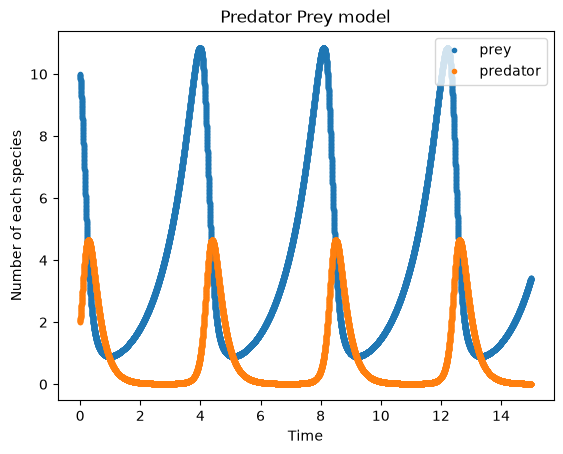

In [16]:
plt.plot(time, x_rk4, '.', label = 'prey ')
plt.plot(time, y_rk4, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("Time")
plt.ylabel("Number of each species")
#title
plt.title("Predator Prey model")

Text(0.5, 1.0, 'Predator Prey model')

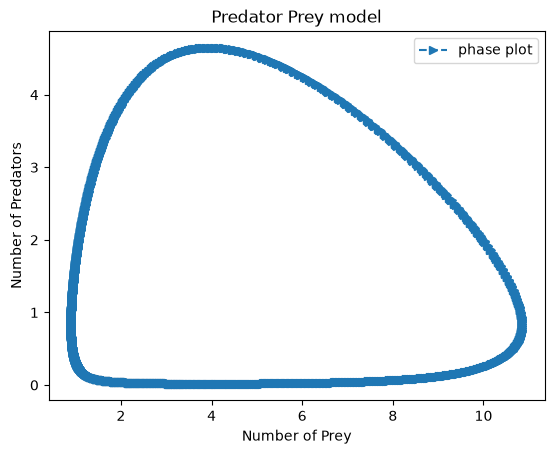

In [17]:
plt.plot(x_rk4, y_rk4, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("Number of Prey")
plt.ylabel("Number of Predators")
#title
plt.title("Predator Prey model")

In [18]:
T  = 15.0                           
dt = 0.0001            #100 times smaller                  
N  = int(T/dt) + 1                   

# initial conditions
x0 = 10.
y0 = 2. 
t0 = 0.

# initialize the array containing the solution for each time-step
u_rk4 = np.zeros((N, 2))

# input initial conditions
u_rk4[0] = np.array([x0, y0])

for n in range(N - 1):
    u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

time = np.linspace(0.0, T, N)
x_rk4 = u_rk4[:, 0]
y_rk4 = u_rk4[:, 1]

Text(0.5, 1.0, 'Predator Prey model')

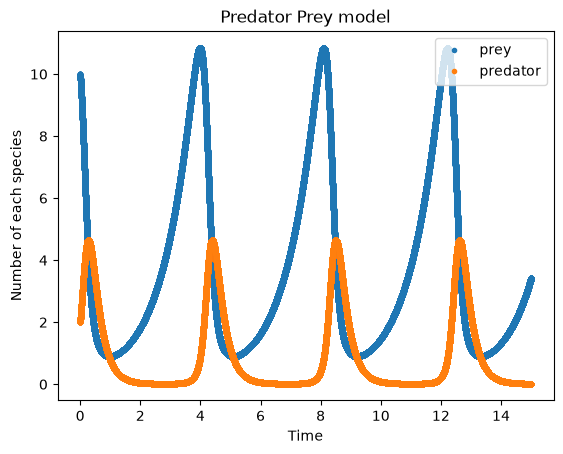

In [19]:
plt.plot(time, x_rk4, '.', label = 'prey ')
plt.plot(time, y_rk4, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("Time")
plt.ylabel("Number of each species")
#title
plt.title("Predator Prey model")

Text(0.5, 1.0, 'Predator Prey model')

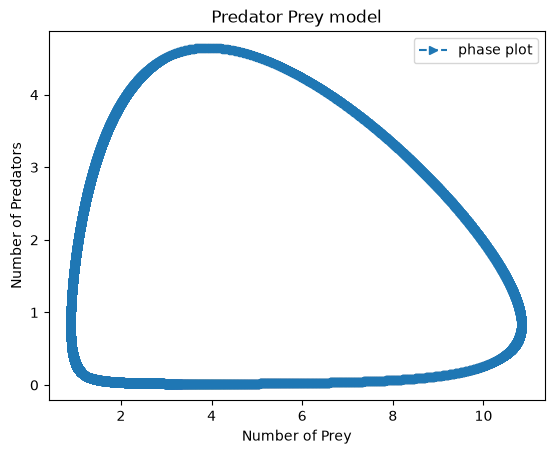

In [20]:
plt.plot(x_rk4, y_rk4, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("Number of Prey")
plt.ylabel("Number of Predators")
#title
plt.title("Predator Prey model")

With the RK4 method, the cycles remain consistent with larger dt (10 times bigger). I think this method gives less error. The Euler method is more sensitive to dt changes.

#### E.4 Exploring parameter space
Vary the interactions between species by changing $\alpha, \beta, \gamma, \delta$ and see what happens to the population evolution as well as phase plots. How does changing each parameter individually affect the system?

In [22]:
alpha = 6.   #alpha changed
beta = 1.2
gamma = 4.
delta = 1

In [23]:
def f(u):
    x = u[0]
    y = u[1]
    return np.array([x * (alpha - beta * y), -y * (gamma - delta * x)])

In [24]:
T  = 15.0                          
dt = 0.01                           
N  = int(T/dt) + 1                  

x0 = 10. 
y0 = 2. 
t0 = 0.

u_rk4 = np.zeros((N, 2))

u_rk4[0] = np.array([x0, y0])

for n in range(N - 1):
    u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

time = np.linspace(0.0, T, N)
x_rk4 = u_rk4[:, 0]
y_rk4 = u_rk4[:, 1]

Text(0.5, 1.0, 'Predator Prey model')

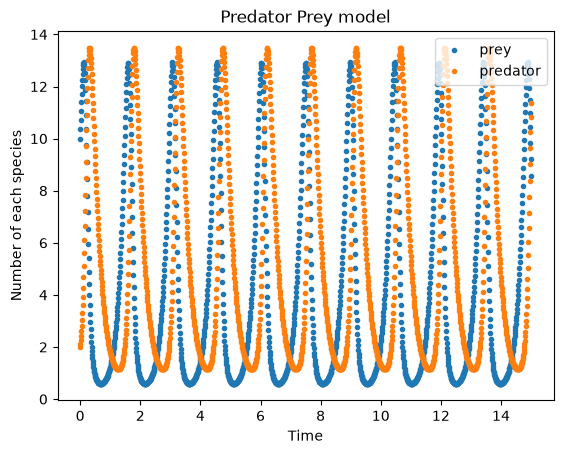

In [25]:
plt.plot(time, x_rk4, '.', label = 'prey ')
plt.plot(time, y_rk4, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("Time")
plt.ylabel("Number of each species")
#title
plt.title("Predator Prey model")

Text(0.5, 1.0, 'Predator Prey model')

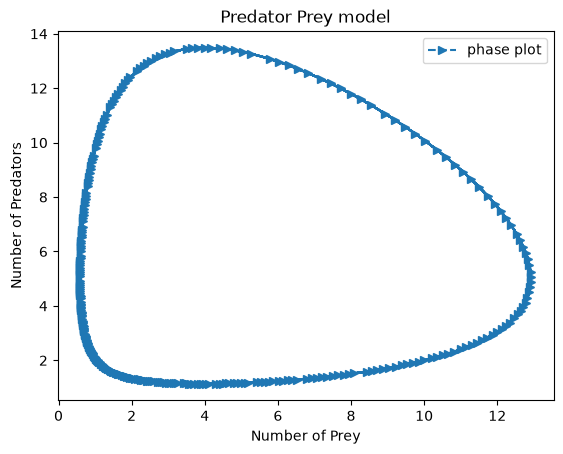

In [26]:
plt.plot(x_rk4, y_rk4, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("Number of Prey")
plt.ylabel("Number of Predators")
#title
plt.title("Predator Prey model")

Increasing alpha allows prey to reproduce faster, providing more food for predators. The cycles became shorter, producing more cycles over the same time period.

In [27]:
alpha = 1.    
beta = 3.  # beta changed 
gamma = 4.
delta = 1

In [28]:
def f(u):
    x = u[0]
    y = u[1]
    return np.array([x * (alpha - beta * y), -y * (gamma - delta * x)])

T  = 15.0                        
dt = 0.01                           
N  = int(T/dt) + 1                  

x0 = 10. 
y0 = 2. 
t0 = 0.

u_rk4 = np.zeros((N, 2))

u_rk4[0] = np.array([x0, y0])

for n in range(N - 1):
    u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

time = np.linspace(0.0, T, N)
x_rk4 = u_rk4[:, 0]
y_rk4 = u_rk4[:, 1]

Text(0.5, 1.0, 'Predator Prey model')

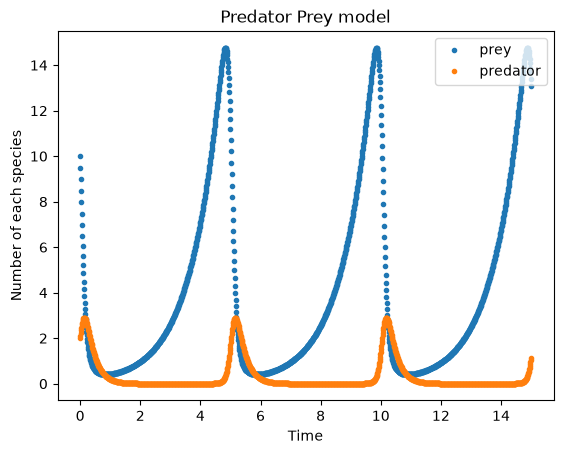

In [29]:
plt.plot(time, x_rk4, '.', label = 'prey ')
plt.plot(time, y_rk4, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("Time")
plt.ylabel("Number of each species")
#title
plt.title("Predator Prey model")

Text(0.5, 1.0, 'Predator Prey model')

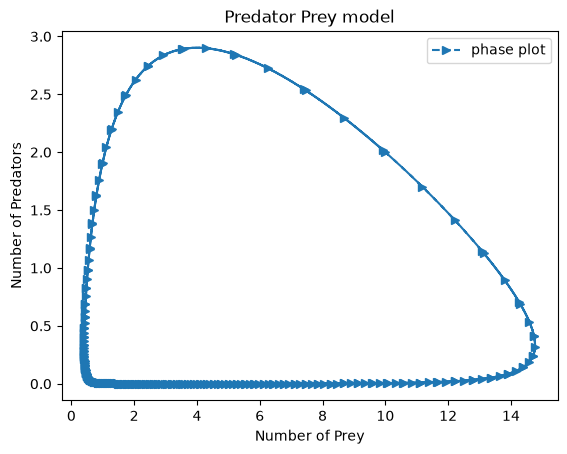

In [30]:
plt.plot(x_rk4, y_rk4, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("Number of Prey")
plt.ylabel("Number of Predators")
#title
plt.title("Predator Prey model")

Increasing beta increases prey loss through predation. The cycles became longer, producing fewer cycles over the same time period. 

In [31]:
alpha = 1.    
beta = 1.2
gamma = 8.   #gamma changed 
delta = 1

In [32]:
T  = 15.0                        
dt = 0.01                           
N  = int(T/dt) + 1                  

x0 = 10. 
y0 = 2. 
t0 = 0.

u_rk4 = np.zeros((N, 2))

u_rk4[0] = np.array([x0, y0])

for n in range(N - 1):
    u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

time = np.linspace(0.0, T, N)
x_rk4 = u_rk4[:, 0]
y_rk4 = u_rk4[:, 1]

Text(0.5, 1.0, 'Predator Prey model')

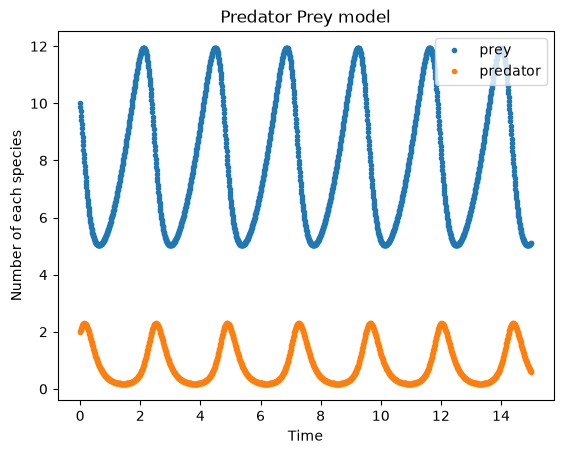

In [33]:
plt.plot(time, x_rk4, '.', label = 'prey ')
plt.plot(time, y_rk4, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("Time")
plt.ylabel("Number of each species")
#title
plt.title("Predator Prey model")

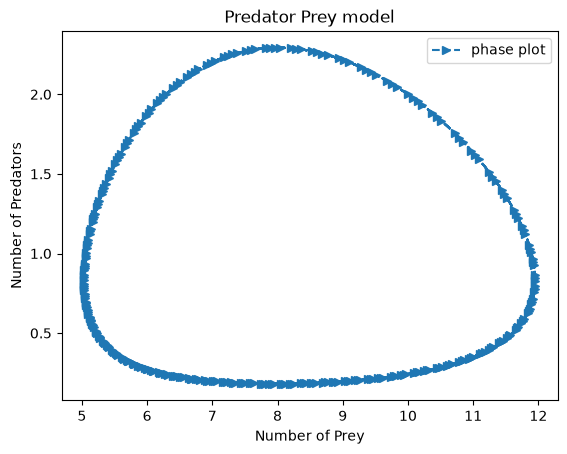

In [34]:
plt.plot(x_rk4, y_rk4, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("Number of Prey")
plt.ylabel("Number of Predators")
#title
plt.title("Predator Prey model");

Increasing gamma increases predator deaths. A decline in predators can reduce pressure on prey, allowing the prey population to recover.

In [35]:
alpha = 1.    
beta = 1.2
gamma = 4.   
delta = 3    #delta changed

In [36]:
T  = 15.0                        
dt = 0.01                           
N  = int(T/dt) + 1                  

x0 = 10. 
y0 = 2. 
t0 = 0.

u_rk4 = np.zeros((N, 2))

u_rk4[0] = np.array([x0, y0])

for n in range(N - 1):
    u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

time = np.linspace(0.0, T, N)
x_rk4 = u_rk4[:, 0]
y_rk4 = u_rk4[:, 1]

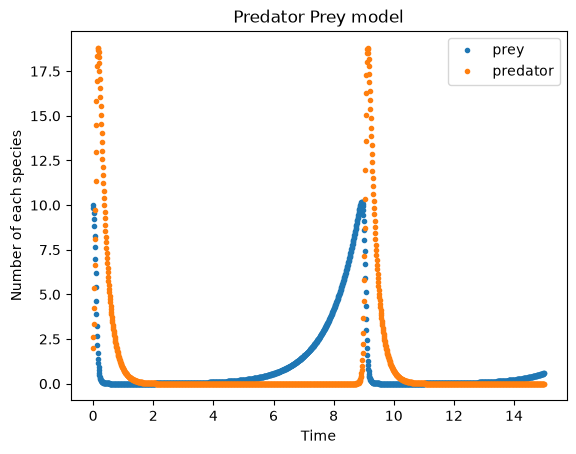

In [37]:
plt.plot(time, x_rk4, '.', label = 'prey ')
plt.plot(time, y_rk4, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("Time")
plt.ylabel("Number of each species")
#title
plt.title("Predator Prey model");

plt.plot(x_rk4, y_rk4, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("Number of Prey")
plt.ylabel("Number of Predators")
#title
plt.title("Predator Prey model")

Increasing delta allows the predator population to grow faster from feeding on prey. More predators can then reduce the prey population. The cycles became longer, producing fewer cycles, and predator population peaks were higher than prey peaks.

#### E.5 (Advanced, required for grad students)
Modify the differential equations to include other types of interactions. See advanced predator prey example link at the top for ideas. You might add in a self-eating (i.e. $-ay^2$) term into the predator equation. Or do the zombie apocalypse example linked above.

Doing the Zombie apocalypse example based on a system:

dS/dt = P - BSZ - dS dZ/dt = BSZ + GR - ASZ dR/dt = dS + ASZ - GR


S: the number of susceptible victims

Z: the number of zombies

R: the number of people "killed"

P: the population birth rate

d: the chance of a natural death

B: the chance the "zombie disease" is transmitted (an alive person becomes a zombie)

G: the chance a dead person is resurrected into a zombie

In [41]:
from scipy.integrate import odeint
plt.ion()
plt.rcParams['figure.figsize'] = 10, 8

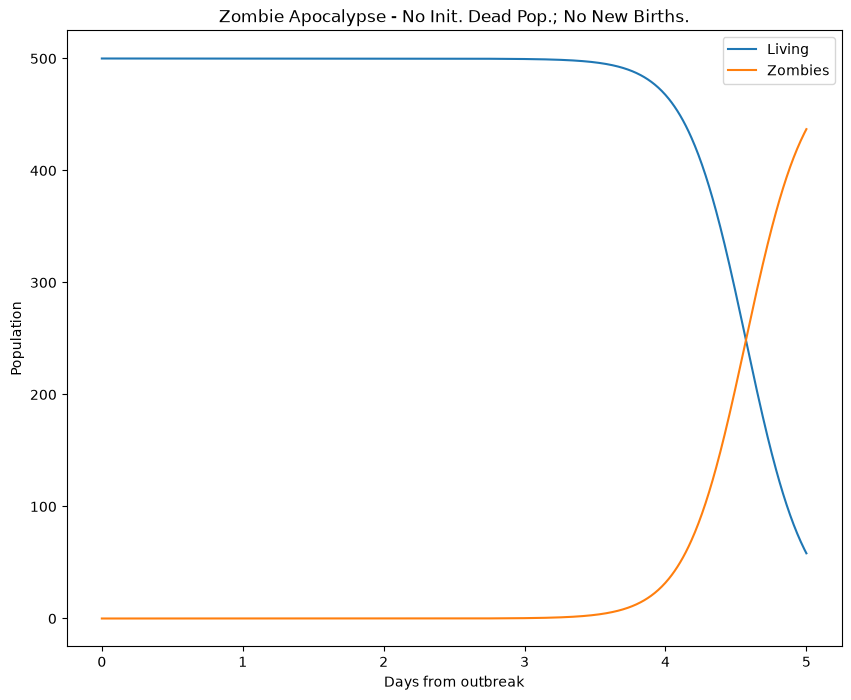

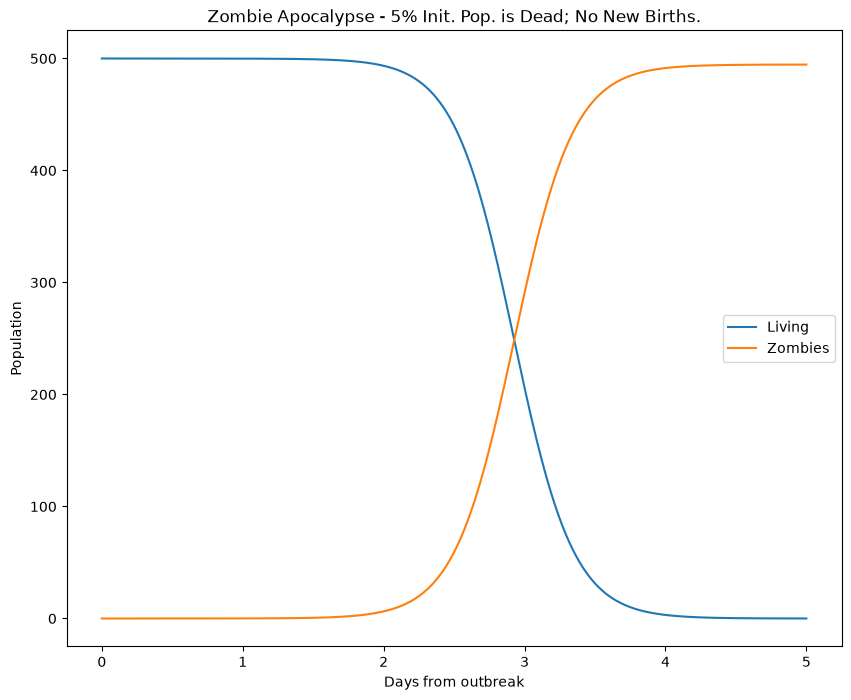

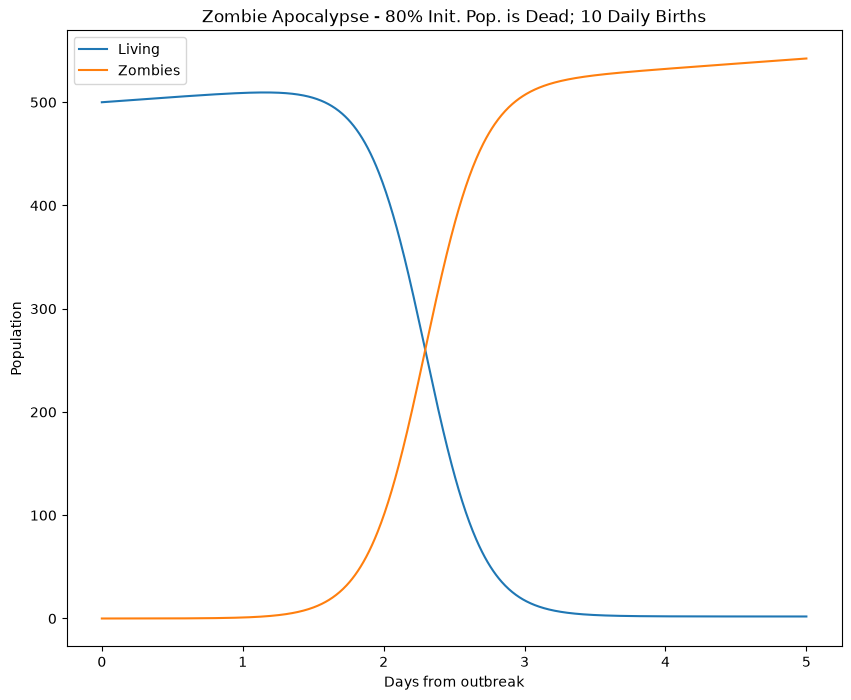

In [51]:
# zombie apocalypse modeling changing the %dead and the number of births
plt.ion()
plt.rcParams['figure.figsize'] = 10, 8

P = 0      # birth rate
d = 0.0001  # natural death percent (per day)
B = 0.0095  # transmission percent  (per day)
G = 0.0001  # resurect percent (per day)
A = 0.0001  # destroy percent  (per day)

# solve the system dy/dt = f(y, t)
def f(y, t):
     Si = y[0]
     Zi = y[1]
     Ri = y[2]
     # the model equations (see Munz et al. 2009)
     f0 = P - B*Si*Zi - d*Si
     f1 = B*Si*Zi + G*Ri - A*Si*Zi
     f2 = d*Si + A*Si*Zi - G*Ri
     return [f0, f1, f2]

# initial conditions
S0 = 500.              # initial population
Z0 = 0                 # initial zombie population
R0 = 0                 # initial death population
y0 = [S0, Z0, R0]     # initial condition vector
t  = np.linspace(0, 5., 1000)         # time grid

# solve the DEs
soln = odeint(f, y0, t)
S = soln[:, 0]
Z = soln[:, 1]
R = soln[:, 2]

# plot results
plt.figure()
plt.plot(t, S, label='Living')
plt.plot(t, Z, label='Zombies')
plt.xlabel('Days from outbreak')
plt.ylabel('Population')
plt.title('Zombie Apocalypse - No Init. Dead Pop.; No New Births.')
plt.legend(loc=0)

# change the initial conditions (different from the example, I increased the dead percent)
R0 = 0.05*S0   # 5% of initial pop is dead
y0 = [S0, Z0, R0]

# solve the DEs
soln = odeint(f, y0, t)
S = soln[:, 0]
Z = soln[:, 1]
R = soln[:, 2]

plt.figure()
plt.plot(t, S, label='Living')
plt.plot(t, Z, label='Zombies')
plt.xlabel('Days from outbreak')
plt.ylabel('Population')
plt.title('Zombie Apocalypse - 5% Init. Pop. is Dead; No New Births.')
plt.legend(loc=0)

# change the initial conditions (different from the example, I increased the births and Increased the dead percent)
R0 = 0.80*S0   # 80% of initial pop is dead
P  = 10        # 10 new births daily
y0 = [S0, Z0, R0]

# solve the DEs
soln = odeint(f, y0, t)
S = soln[:, 0]
Z = soln[:, 1]
R = soln[:, 2]

plt.figure()
plt.plot(t, S, label='Living')
plt.plot(t, Z, label='Zombies')
plt.xlabel('Days from outbreak')
plt.ylabel('Population')
plt.title('Zombie Apocalypse - 80% Init. Pop. is Dead; 10 Daily Births')
plt.legend(loc=0)